# ESG Investing: Performance, Risk, and Real Purchasing Power Analysis
This project analyzes whether sustainable investing affects financial performance, risk, and real purchasing power compared with traditional market investing in the United States and Canada.

The objective is to evaluate whether incorporating **best-in-class** Environmental, Social, and Governance (ESG) criteria—selecting industry leaders with lower carbon intensity and stronger governance rather than applying blanket sector exclusions—provides a competitive risk-return profile relative to conventional market benchmarks. The analysis compares **SPY vs. ESGU** in the U.S. market and **XIU.TO vs. XEN.TO** in the Canadian market.

Using five years of historical market data (2021–2026), this project will:

1. Import and clean adjusted closing price data for the four ETFs.
2. Calculate daily returns and analyze their statistical characteristics.
3. Simulate the nominal growth of a **\$10,000 initial investment** in each ETF.
4. Adjust 2026 ending balances for **post-COVID cumulative inflation** to measure real wealth creation in **2021 constant dollars**.
5. Measure and compare Compound Annual Growth Rates (**Nominal and Real CAGR**) and annualized volatility.
6. Evaluate risk-adjusted performance using the **Sharpe Ratio** (benchmarked against 3-month government Treasury Bill yields).
7. Visualize cumulative portfolio growth over the 5-year period.
8. Assess whether ESG investing has historically resulted in a different risk-return trade-off compared with traditional market exposure.

*Note: Performance and \$10,000 growth simulations are evaluated in local currency (USD for U.S. ETFs; CAD for Canadian ETFs), deflated using country-specific Consumer Price Index (CPI) series, and benchmarked against local 3-month Treasury Bill yields to isolate pure equity performance from foreign exchange (FX) fluctuations.*

In [1]:
# Import required libraries for financial data extraction, analysis, and visualization
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# 1a. Import adjusted closing price data for the four ETFs
# Tickers for comparison: Traditional vs. Best-in-Class ESG in the U.S. and Canada
# SPY: U.S. Traditional Market (S&P 500)
# ESGU: U.S. ESG Market (MSCI USA Extended ESG Focus - Best-in-Class)
# XIU.TO: Canada Traditional Market (S&P/TSX 60)
# XEN.TO: Canada ESG Market (Jantzi Social Index - Best-in-Class)
tickers = ["SPY", "ESGU", "XIU.TO", "XEN.TO"]

# Download 5 years of historical data (fixed window for reproducibility)
# auto_adjust=True cleans the data and applies dividends/splits directly to the 'Close' column
data = yf.download(tickers, start="2021-10-18", end="2026-10-17", auto_adjust=True)['Close']

# Display the first few rows to verify data extraction
data.head()

[*********************100%***********************]  4 of 4 completed


Ticker,ESGU,SPY,XEN.TO,XIU.TO
Date,,,,
2021-10-18,96.447754,418.257904,27.092093,27.636106
2021-10-19,97.141891,421.484680,27.226082,27.757471
2021-10-20,97.479568,423.140198,27.422598,27.878839
2021-10-21,97.714096,424.243835,27.458321,27.922178
2021-10-22,97.564011,423.804230,27.449392,27.939514


In [3]:
# 1b. Clean missing data (Drop rows with NaN due to differing US/CAD market holidays)
data = data.dropna()

# 2. Calculate daily returns (percent change day-over-day)
daily_returns = data.pct_change().dropna()

# Display the first few rows of the daily returns
daily_returns.head()

Ticker,ESGU,SPY,XEN.TO,XIU.TO
Date,,,,
2021-10-19,0.007197,0.007715,0.004946,0.004392
2021-10-20,0.003476,0.003928,0.007218,0.004372
2021-10-21,0.002406,0.002608,0.001303,0.001555
2021-10-22,-0.001536,-0.001036,-0.000325,0.000621
2021-10-25,0.004807,0.005363,0.003580,0.002792


In [4]:
# 3. Simulating the nominal growth of a $10,000 initial investment
initial_investment = 10000

# Add 1 to daily returns to get the multiplier, calculate cumulative product, and multiply by initial cash
portfolio_growth = initial_investment * (1 + daily_returns).cumprod()

# Display the final rows to see the ending nominal balance for each ETF
portfolio_growth.tail()

Ticker,ESGU,SPY,XEN.TO,XIU.TO
Date,,,,
2026-10-09,17680.038919,18614.591614,20146.100491,19206.758321
2026-10-13,17655.154411,18601.202804,20264.216024,19452.811972
2026-10-14,17424.977851,18400.129875,20046.440246,19286.363386
2026-10-15,17493.409062,18452.489972,20109.188507,19572.221641
2026-10-16,17299.522212,18248.310256,20467.227009,19601.168561


In [5]:
# 4. Adjust 2026 ending balances for post-COVID cumulative inflation (2021 Constant Dollars)
trading_days = 252
years = 5.0
ending_nominal = portfolio_growth.iloc[-1]

# Official Seasonally Adjusted CPI Index Levels (5-Year Annualized Inflation CAGR):
# - U.S. CPI (FRED CPIAUCSL): Oct 2021 (276.550) -> Sep 2026 (336.298) = 3.99% (0.0399)
# - Canada CPI (Bank of Canada V41690914): Oct 2021 (143.9) -> Aug 2026 (169.3) = 3.30% (0.0330)
us_cpi_cagr = (336.298 / 276.550) ** (1 / years) - 1
ca_cpi_cagr = (169.3 / 143.9) ** (1 / years) - 1

inflation_rates = pd.Series({"ESGU": us_cpi_cagr, "SPY": us_cpi_cagr, "XEN.TO": ca_cpi_cagr, "XIU.TO": ca_cpi_cagr})
ending_real_2021 = ending_nominal / ((1 + inflation_rates) ** years)

# 5. Measure Compound Annual Growth Rates (Nominal & Real CAGR) and Annualized Volatility
nominal_cagr = (ending_nominal / initial_investment) ** (1 / years) - 1
real_cagr = (1 + nominal_cagr) / (1 + inflation_rates) - 1
annualized_volatility = daily_returns.std() * np.sqrt(trading_days)

# 6. Evaluate risk-adjusted performance using the Sharpe Ratio
# 5-year mean 3-Month Treasury Bill yields (2021-2026):
# - U.S. 13-Week T-Bill (Yahoo Finance ^IRX, auto_adjust=True): 3.79% (0.0379)
# - Canada 3-Month T-Bill Auction Yields (Bank of Canada V80691303): 3.20% (0.0320)
rf_rates = pd.Series({"ESGU": 0.0379, "SPY": 0.0379, "XEN.TO": 0.0320, "XIU.TO": 0.0320})
annualized_return = daily_returns.mean() * trading_days
sharpe_ratio = (annualized_return - rf_rates) / annualized_volatility

# Creating a clean, institutional-grade summary table
metrics_summary = pd.DataFrame({
    "2026 Nominal Value ($)": ending_nominal.round(2),
    "2021 Real Value ($)": ending_real_2021.round(2),
    "Nominal CAGR (%)": (nominal_cagr * 100).round(2),
    "Real CAGR (%)": (real_cagr * 100).round(2),
    "Annualized Volatility (%)": (annualized_volatility * 100).round(2),
    "Sharpe Ratio": sharpe_ratio.round(2)
})

# Display the summary table
metrics_summary

,2026 Nominal Value ($),2021 Real Value ($),Nominal CAGR (%),Real CAGR (%),Annualized Volatility (%),Sharpe Ratio
Ticker,,,,,,
ESGU,17299.52,14226.02,11.59,7.30,17.57,0.51
SPY,18248.31,15006.25,12.78,8.46,17.31,0.58
XEN.TO,20467.23,17396.54,15.40,11.71,14.14,0.88
XIU.TO,19601.17,16660.41,14.41,10.75,13.05,0.88


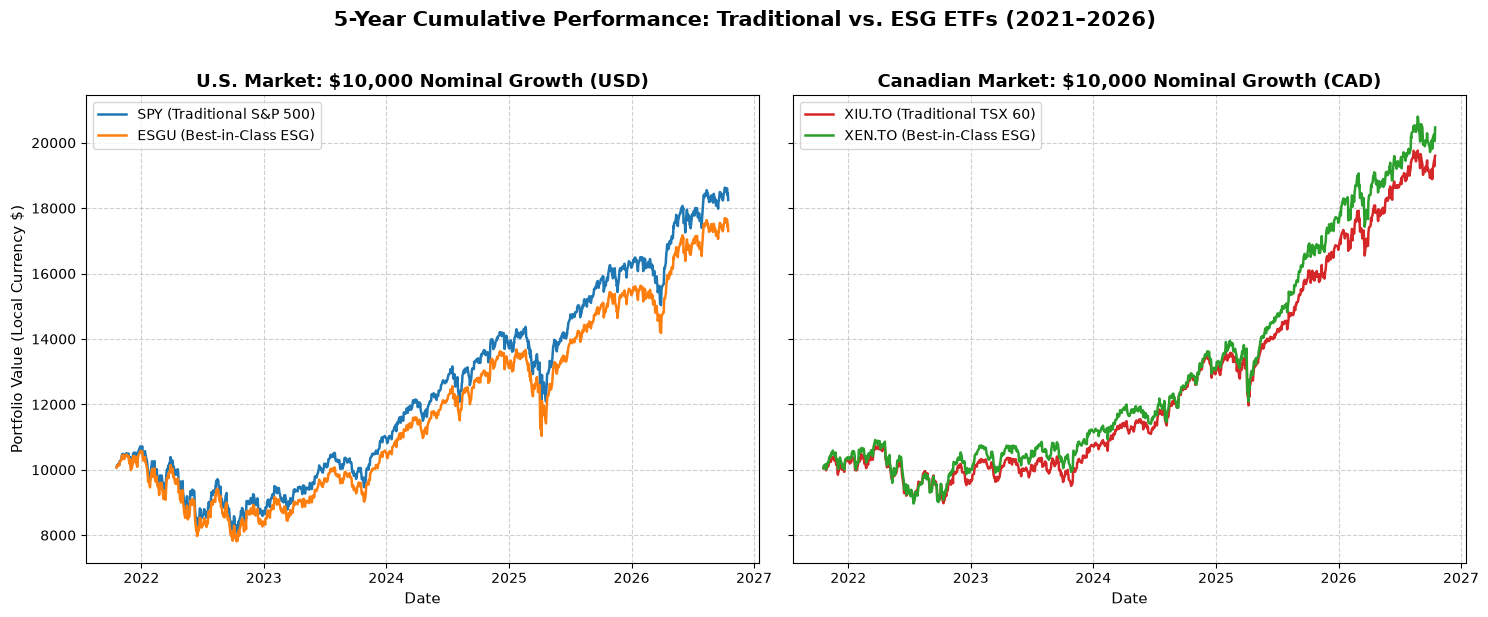

In [6]:
# 7. Visualization: Nominal Performance of a $10,000 Initial Investment (Separated by Currency/Market)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# Panel 1: U.S. Market (USD)
axes[0].plot(portfolio_growth.index, portfolio_growth["SPY"], label="SPY (Traditional S&P 500)", color="#1f77b4", linewidth=1.8)
axes[0].plot(portfolio_growth.index, portfolio_growth["ESGU"], label="ESGU (Best-in-Class ESG)", color="#ff7f0e", linewidth=1.8)
axes[0].set_title("U.S. Market: $10,000 Nominal Growth (USD)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Date", fontsize=11)
axes[0].set_ylabel("Portfolio Value (Local Currency $)", fontsize=11)
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Panel 2: Canadian Market (CAD)
axes[1].plot(portfolio_growth.index, portfolio_growth["XIU.TO"], label="XIU.TO (Traditional TSX 60)", color="#d62728", linewidth=1.8)
axes[1].plot(portfolio_growth.index, portfolio_growth["XEN.TO"], label="XEN.TO (Best-in-Class ESG)", color="#2ca02c", linewidth=1.8)
axes[1].set_title("Canadian Market: $10,000 Nominal Growth (CAD)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Date", fontsize=11)
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("5-Year Cumulative Performance: Traditional vs. ESG ETFs (2021–2026)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 8. Conclusion: Comparative Performance and Risk-Return Profile of ESG vs. Traditional ETFs

The 5-year historical analysis (October 2021–October 2026) illustrates how the performance and risk-adjusted efficiency of best-in-class sustainable ETFs relative to traditional market benchmarks vary across the U.S. and Canadian equity markets.

**1. The Canadian Market Comparison (XEN.TO vs. XIU.TO)**: 
Within the 2021–2026 sample examined, the Canadian ESG ETF (**XEN.TO**) outperformed the traditional S&P/TSX 60 benchmark (**XIU.TO**) in both cumulative growth and compound annual return (**15.40% vs. 14.41% Nominal CAGR**; **11.71% vs. 10.75% Real CAGR**). Although XEN.TO exhibited slightly higher annualized volatility (**14.14% vs. 13.05%**), benchmarking against the 5-year average Canadian 3-month Treasury Bill yield (3.20%) resulted in an identical **Sharpe Ratio of 0.88 for both funds**. Within this historical sample, applying best-in-class ESG screening in Canada generated higher total returns while maintaining equivalent risk-adjusted efficiency.

**2. The U.S. Market Comparison (ESGU vs. SPY)**: 
In the U.S. market, the conventional S&P 500 benchmark (**SPY**) maintained a modest advantage over its ESG counterpart (**ESGU**), delivering a **12.78% vs. 11.59% Nominal CAGR** and a higher Sharpe Ratio (**0.58 vs. 0.51**, using a 3.79% U.S. 3-month T-Bill average). While both funds experienced similar annualized volatility (**17.31% vs. 17.57%**), differences in underlying index construction and sector weightings favored the traditional benchmark over this specific five-year period.

**3. Real Purchasing Power (The Post-COVID Inflation Test)**: 
To measure real wealth creation across the post-COVID inflationary cycle—where seasonally adjusted annualized CPI inflation averaged **3.99% in the U.S.** and **3.30% in Canada**—the 2026 ending balances were deflated into **2021 constant dollars**:
* **Canada (CAD)**: A \$10,000 initial investment in **XEN.TO** grew to **\$20,467.23 nominally**, representing **\$17,396.54 in 2021 purchasing power** (**+11.71% Real CAGR**), compared to **\$19,601.16 nominally** and **\$16,660.41 in 2021 dollars** (**+10.75% Real CAGR**) for **XIU.TO**.
* **United States (USD)**: A \$10,000 initial investment in **SPY** grew to **\$18,248.31 nominally**, or **\$15,006.25 in 2021 purchasing power** (**+8.46% Real CAGR**), compared to **\$17,299.52 nominally** and **\$14,226.02 in 2021 dollars** (**+7.30% Real CAGR**) for **ESGU**.

**Summary Takeaway**: 
The empirical evidence in this sample indicates that best-in-class ESG investing does not entail a systematic financial penalty or automatic premium. Because outcomes diverged across borders—with **XEN.TO** outperforming its traditional peer in Canada and **ESGU** slightly trailing **SPY** in the U.S.—investors should evaluate sustainable funds through a market-specific and structural lens, while recognizing that all four strategies successfully preserved and grew real purchasing power above post-COVID inflation.

---

### Data Sources & Methodological Notes
* **Equity Prices (`yfinance`)**: Daily closing prices adjusted for dividends and splits (`auto_adjust=True`) over the fixed 5-year window (`2021-10-18` to `2026-10-16`).
* **Inflation Rates (Seasonally Adjusted CPI CAGR)**: Computed via `CPI_CAGR = (CPI_end / CPI_start)^(1/5) - 1` using official seasonally adjusted series for cross-country consistency. Because monthly CPI releases lag daily equity data by 1–2 months, the latest available observations (Oct 2021–Sep 2026 for the U.S., and Oct 2021–Aug 2026 for Canada) are annualized over `years = 5.0` as a practical approximation for the 5-year window:
    * *U.S. CPI (Seasonally Adjusted)*: [FRED (`CPIAUCSL`)](https://fred.stlouisfed.org/series/CPIAUCSL) from Oct 2021 (`276.550`) to Sep 2026 (`336.298`) = **3.99% annualized**.
    * *Canada CPI (Seasonally Adjusted)*: [Bank of Canada / StatCan (`V41690914`, Total CPI SA)](https://www.bankofcanada.ca/rates/price-indexes/cpi/) from Oct 2021 (`143.9`) to Aug 2026 (`169.3`) = **3.30% annualized**.
* **Risk-Free Rates (`rf_rates`)**: 5-year arithmetic mean of 3-month sovereign Treasury Bill yields (Oct 2021–Oct 2026):
    * *U.S. 3-Month T-Bill*: [Yahoo Finance (`^IRX`, 13-Week Treasury Bill, `auto_adjust=True`)](https://finance.yahoo.com/quote/%5EIRX/) = **3.79% average**.
    * *Canada 3-Month T-Bill*: [Bank of Canada (`V80691303`, 3-Month T-Bill Auction Average Yields)](https://www.bankofcanada.ca/rates/interest-rates/t-bill-yields/) = **3.20% average**.
* **Analytical Scope**: Regional policy frameworks (e.g., carbon pricing or sector regulations) serve as qualitative background; this study is a descriptive historical comparison across four ETFs rather than a causal factor-attribution model.